<a href="https://colab.research.google.com/github/saravaneswaran-coder/Logistic-Regression-from-scratch-/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

iteration 0 : cost 1.4603
iteration 1000 : cost 0.5977
iteration 2000 : cost 0.3621
iteration 3000 : cost 0.2835
iteration 4000 : cost 0.2448
iteration 5000 : cost 0.2214
iteration 6000 : cost 0.2055
iteration 7000 : cost 0.1937
iteration 8000 : cost 0.1846
iteration 9000 : cost 0.1771
iteration 10000 : cost 0.1710
iteration 11000 : cost 0.1657
iteration 12000 : cost 0.1611
iteration 13000 : cost 0.1571
iteration 14000 : cost 0.1535
iteration 15000 : cost 0.1503
iteration 16000 : cost 0.1473
iteration 17000 : cost 0.1446
iteration 18000 : cost 0.1422
iteration 19000 : cost 0.1399
iteration 20000 : cost 0.1378
iteration 21000 : cost 0.1358
iteration 22000 : cost 0.1339
iteration 23000 : cost 0.1322
iteration 24000 : cost 0.1306
iteration 25000 : cost 0.1291
iteration 26000 : cost 0.1276
iteration 27000 : cost 0.1262
iteration 28000 : cost 0.1249
iteration 29000 : cost 0.1237
iteration 30000 : cost 0.1225
iteration 31000 : cost 0.1214
iteration 32000 : cost 0.1203
iteration 33000 : cost 

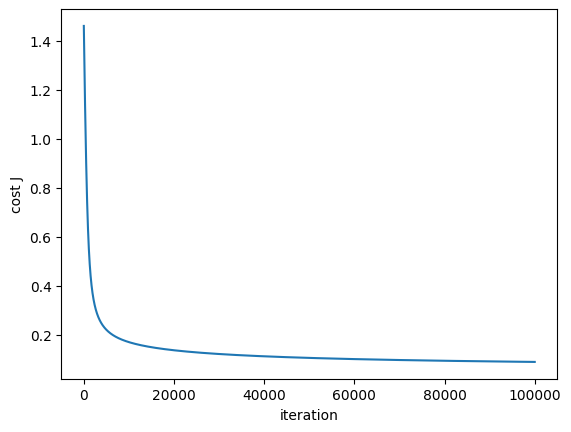

Train accuracy: 0.9802
Test accuracy: 0.9737


In [19]:
import numpy as np
import math
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

#Seperating teh dataset for train and test with 80:20 ratio
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Feature Scaling
mean_1 = X_tr.mean(axis = 0)
deno_1 = X_tr.max(axis = 0) - X_tr.min(axis=0)
X_train = (X_tr - mean_1)/deno_1
X_test = (X_te - mean_1)/deno_1

#Parameters
rng = np.random.default_rng(0)
w = rng.random(X_train.shape[1])
b = 0.9
alpha = 0.01
m = X_train.shape[0]
iterations = 100000
cost_history = []

for iter in range(iterations):
  z = np.dot(X_train,w) + b
  y_hat = 1/(1+ np.exp(-z))

  eps = 1e-12
  y_hat = np.clip(y_hat, eps, 1 - eps)

  loss = (-y_train)*(np.log(y_hat)) - (1-y_train)*(np.log(1-y_hat))
  j_wb = np.sum(loss)/m
  cost_history.append(j_wb)

  dw = np.dot((y_hat - y_train).T,X_train)
  dw = dw/m
  db = np.sum(y_hat - y_train)
  db = db/m
  w = w - alpha*dw
  b = b - alpha*db

  if iter%1000 == 0:
    print(f"iteration {iter} : cost {j_wb:.4f}")


import matplotlib.pyplot as plt
plt.plot(cost_history)
plt.xlabel("iteration"); plt.ylabel("cost J")
plt.show()


#Calculating Model Accuracy with train dataset
z_train = np.dot(X_train, w) + b
y_prob_train = 1 / (1 + np.exp(-z_train))

y_pred_train = (y_prob_train >= 0.5).astype(int)

train_acc = np.mean(y_pred_train == y_train)
print(f"Train accuracy: {train_acc:.4f}")


#Calculating Model accuracy with test dataset
z_test = np.dot(X_test, w) + b
y_prob = 1 / (1 + np.exp(-z_test))

y_pred = (y_prob >= 0.5).astype(int)

accuracy_1 = np.mean(y_pred == y_test)
print(f"Test accuracy: {accuracy_1:.4f}")





